# Example Use Case - Multi-Agent Code Review Assistant

## Context

This use case demonstrates a multi-agent system that reviews and improves Python code through a structured pipeline of LLM agents. It mimics a real-world collaborative software review process with three key roles:

- **Code Reviewer Agent**: Analyzes the input code for bugs, logic errors, and best practices.
- **Linter Agent**: Suggests improvements for code style and formatting (e.g., PEP8).
- **Final Editor Agent**: Synthesizes feedback from both agents to rewrite and return a cleaner, improved version of the code.

We are leveraging LangGraph to manage the flow of data and control transitions between these agents in a stateful, declarative way.


## Initial Setup

In [1]:
import os, getpass
from dotenv import load_dotenv 
load_dotenv(override=True)

True

In [2]:
from typing import TypedDict, Annotated, Optional
from langgraph.graph import StateGraph, END
from langchain_core.messages import HumanMessage
from langchain_core.prompts import PromptTemplate
import gradio as gr

In [3]:
#Check for Google (Gemini) API Key
if "GOOGLE_API_KEY" not in os.environ:
    os.environ["GOOGLE_API_KEY"] = getpass.getpass("Google API Key: ")

## Chat Models

In [4]:
from langchain.chat_models import init_chat_model

model_name = "gemini-flash-latest"
llm = init_chat_model(model_name, model_provider="google_genai") #Gemini replaces Groq/Llama here (other options: gemini-flash-lite-latest, gemini-pro-latest)

In [5]:
# --- Define strongly typed state ---
class CodeReviewState(TypedDict, total=False):
    code: Annotated[str, "The original code input from the user"]
    review_feedback: Annotated[Optional[str], "Feedback from the code reviewer agent"]
    linter_feedback: Annotated[Optional[str], "Feedback from the linter agent"]
    final_code: Annotated[Optional[str], "Rewritten code from the final editor agent"]

In [6]:
# --- Agent 1: Code Reviewer ---
def code_reviewer_agent(state: CodeReviewState) -> CodeReviewState:
    prompt = PromptTemplate.from_template(
        """
        You are a senior software engineer. Review the following code for bugs, logic issues, and best practices.

        Code:
        {code}
        
        Return bullet points of feedback.
        """
    )
    output = llm.invoke([HumanMessage(content=prompt.format(code=state['code']))])
    state['review_feedback'] = output.text
    return state

In [7]:
# --- Agent 2: Linter Agent ---
def linter_agent(state: CodeReviewState) -> CodeReviewState:
    prompt = PromptTemplate.from_template(
        """
        You are a Python linter. Suggest improvements to style and formatting for the following code:

        Code:
        {code}

        Respond in bullet points.
        """
    )
    output = llm.invoke([HumanMessage(content=prompt.format(code=state['code']))])
    state['linter_feedback'] = output.text
    return state

In [8]:
# --- Agent 3: Final Editor Agent ---
def final_editor_agent(state: CodeReviewState) -> CodeReviewState:
    prompt = PromptTemplate.from_template(
        """
        Combine the following feedback into a concise, edited version of the original code.

        Original Code:
        {code}

        Code Review Feedback:
        {review_feedback}

        Linter Feedback:
        {linter_feedback}

        Return the improved version of the code only.
        """
    )
    output = llm.invoke([
        HumanMessage(content=prompt.format(
            code=state['code'],
            review_feedback=state['review_feedback'],
            linter_feedback=state['linter_feedback']
        ))
    ])
    state['final_code'] = output.text
    return state

In [9]:
# --- Build LangGraph ---
graph_builder = StateGraph(CodeReviewState)

graph_builder.add_node("code_review", code_reviewer_agent)
graph_builder.add_node("lint", linter_agent)
graph_builder.add_node("edit", final_editor_agent)

graph_builder.set_entry_point("code_review")
graph_builder.add_edge("code_review", "lint")
graph_builder.add_edge("lint", "edit")
graph_builder.add_edge("edit", END)

graph = graph_builder.compile()

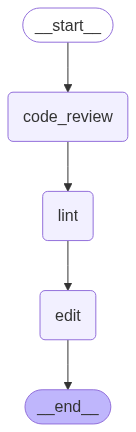

In [11]:
from IPython.display import Image, display
display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [12]:
# --- Gradio Interface ---
def review_code(input_code: str) -> str:
    initial_state: CodeReviewState = {"code": input_code}
    final_state = graph.invoke(initial_state)
    return final_state['final_code']

iface = gr.Interface(
    fn=review_code,
    inputs=gr.Textbox(lines=10, label="Enter Python Code"),
    outputs=gr.Textbox(lines=10, label="Improved Code Output"),
    title="Multi-Agent Code Review Assistant",
    description="Submit Python code to get a review and improved version from an LLM-powered agent pipeline."
)

In [13]:
if __name__ == "__main__":
    iface.launch()

* Running on local URL:  http://127.0.0.1:7886
* To create a public link, set `share=True` in `launch()`.


In [30]:
# # Example
# input_code = """
# def add(x,y):
#  return(x+y)
# """